In [3]:
from pathlib import Path
import os

# Lokasi dataset
DATASET_DIR = Path("../dataset/train")

closed_dir = DATASET_DIR / "Closed_Eyes"
open_dir = DATASET_DIR / "Open_Eyes"

print("Closed Eyes :", len(list(closed_dir.glob("*"))))
print("Open Eyes   :", len(list(open_dir.glob("*"))))
print("Total       :", len(list(closed_dir.glob("*"))) + len(list(open_dir.glob("*"))))

Closed Eyes : 2000
Open Eyes   : 2000
Total       : 4000


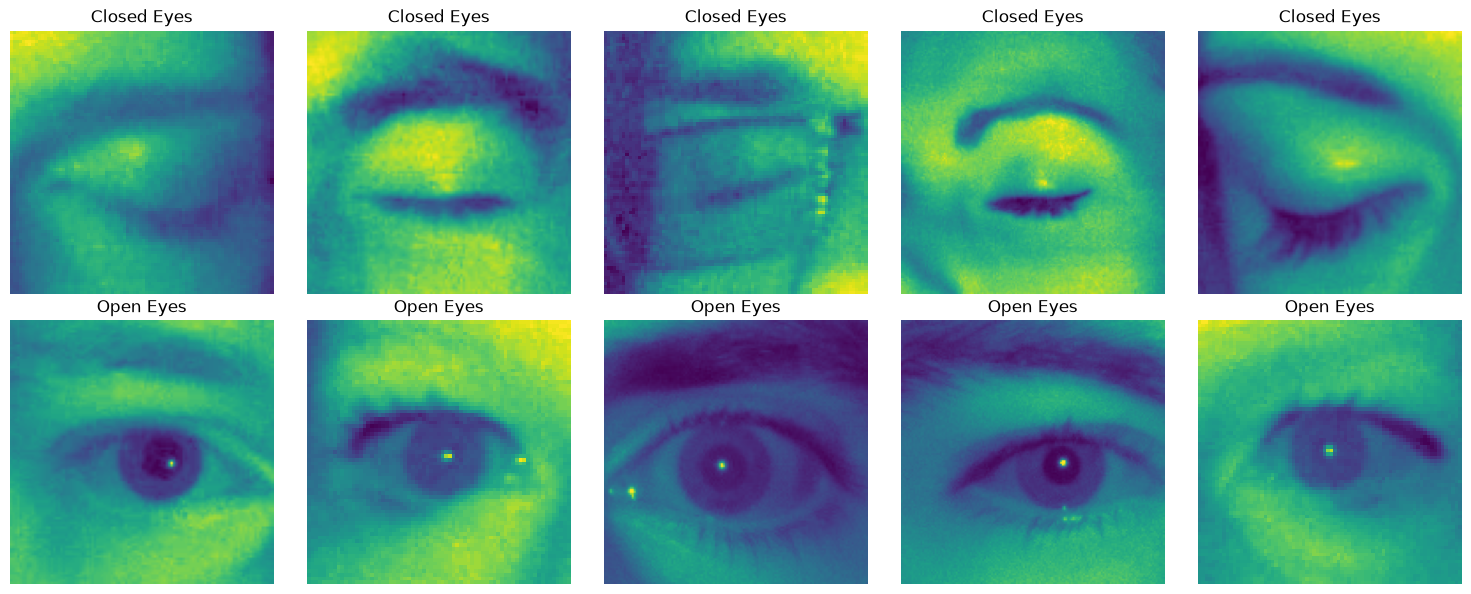

In [4]:
import matplotlib.pyplot as plt
from PIL import Image
import random

closed_images = list(closed_dir.glob("*"))
open_images = list(open_dir.glob("*"))

fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for i in range(5):
    img = Image.open(random.choice(closed_images))
    axes[0, i].imshow(img)
    axes[0, i].set_title("Closed Eyes")
    axes[0, i].axis("off")

    img = Image.open(random.choice(open_images))
    axes[1, i].imshow(img)
    axes[1, i].set_title("Open Eyes")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

In [5]:
from collections import Counter

sizes = []

for img_path in closed_images + open_images:
    try:
        with Image.open(img_path) as img:
            sizes.append(img.size)
    except Exception as e:
        print("Error:", img_path, e)

print("Jumlah gambar terbaca :", len(sizes))
print("Ukuran paling umum    :", Counter(sizes).most_common(10))

Jumlah gambar terbaca : 4000
Ukuran paling umum    : [((95, 95), 100), ((85, 85), 95), ((93, 93), 95), ((97, 97), 93), ((86, 86), 89), ((80, 80), 87), ((94, 94), 87), ((84, 84), 80), ((130, 130), 79), ((98, 98), 77)]


In [9]:
import shutil
import random
from pathlib import Path
from sklearn.model_selection import train_test_split

# Dataset asli
SOURCE_DIR = Path("../dataset/train")

# Folder hasil split
OUTPUT_DIR = Path("../dataset_split")

# Class
classes = ["Closed_Eyes", "Open_Eyes"]

# Pastikan hasil split sebelumnya dihapus
if OUTPUT_DIR.exists():
    shutil.rmtree(OUTPUT_DIR)

# Kumpulkan semua gambar dan label
image_paths = []
labels = []

for class_name in classes:
    class_dir = SOURCE_DIR / class_name

    for image_path in class_dir.iterdir():
        if image_path.is_file():
            image_paths.append(image_path)
            labels.append(class_name)

print("Total gambar:", len(image_paths))
print("Total label :", len(labels))

# Split pertama:
# 70% train
# 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    image_paths,
    labels,
    test_size=0.30,
    random_state=42,
    stratify=labels
)

# Split temporary menjadi:
# 15% validation
# 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("\nHasil split:")
print("Train      :", len(X_train))
print("Validation :", len(X_val))
print("Test       :", len(X_test))

# Fungsi untuk copy file
def copy_dataset(paths, labels, split_name):
    for image_path, label in zip(paths, labels):

        destination = OUTPUT_DIR / split_name / label
        destination.mkdir(parents=True, exist_ok=True)

        shutil.copy2(
            image_path,
            destination / image_path.name
        )

# Copy dataset
copy_dataset(X_train, y_train, "train")
copy_dataset(X_val, y_val, "validation")
copy_dataset(X_test, y_test, "test")

print("\nDataset berhasil di-split!")

Total gambar: 4000
Total label : 4000

Hasil split:
Train      : 2800
Validation : 600
Test       : 600

Dataset berhasil di-split!


In [11]:
import tensorflow as tf

# Ukuran gambar
IMG_SIZE = (64, 64)

# Batch size
BATCH_SIZE = 32

# Lokasi dataset hasil split
DATASET_PATH = "../dataset_split"

# Load training dataset
train_ds = tf.keras.utils.image_dataset_from_directory(
    f"{DATASET_PATH}/train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=True,
    seed=42
)

# Load validation dataset
val_ds = tf.keras.utils.image_dataset_from_directory(
    f"{DATASET_PATH}/validation",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

# Load test dataset
test_ds = tf.keras.utils.image_dataset_from_directory(
    f"{DATASET_PATH}/test",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

print("Class names:", train_ds.class_names)

Found 2800 files belonging to 2 classes.
Found 600 files belonging to 2 classes.
Found 600 files belonging to 2 classes.
Class names: ['Closed_Eyes', 'Open_Eyes']


In [12]:
normalization_layer = tf.keras.layers.Rescaling(
    1.0 / 255
)

train_ds = train_ds.map(
    lambda x, y: (normalization_layer(x), y)
)

val_ds = val_ds.map(
    lambda x, y: (normalization_layer(x), y)
)

test_ds = test_ds.map(
    lambda x, y: (normalization_layer(x), y)
)

print("Normalisasi selesai.")

Normalisasi selesai.


In [13]:
for images, labels in train_ds.take(1):
    print("Image shape :", images.shape)
    print("Label shape :", labels.shape)
    print("Pixel min   :", tf.reduce_min(images).numpy())
    print("Pixel max   :", tf.reduce_max(images).numpy())

Image shape : (32, 64, 64, 3)
Label shape : (32, 1)
Pixel min   : 0.001439951
Pixel max   : 1.0


In [14]:
from tensorflow import keras
from tensorflow.keras import layers

model = keras.Sequential([
    layers.Input(shape=(64, 64, 3)),

    # Feature extraction
    layers.Conv2D(16, (3, 3), activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D(),

    # Classification
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.5),

    layers.Dense(1, activation="sigmoid")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       147,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 171,169 (668.63 KB)

 Trainable params: 171,169 (668.63 KB)

 Non-trainable params: 0 (0.00 B)

In [15]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Model siap untuk training.")

Model siap untuk training.


In [16]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[early_stopping]
)

Epoch 1/20


c:\Users\marce\Documents\ComVis Sleep\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


88/88 ━━━━━━━━━━━━━━━━━━━━ 6s 46ms/step - accuracy: 0.8364 - loss: 0.3383 - val_accuracy: 0.9683 - val_loss: 0.1222
Epoch 2/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.9671 - loss: 0.1042 - val_accuracy: 0.9850 - val_loss: 0.0620
Epoch 3/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.9800 - loss: 0.0687 - val_accuracy: 0.9883 - val_loss: 0.0301
Epoch 4/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.9918 - loss: 0.0285 - val_accuracy: 0.9983 - val_loss: 0.0114
Epoch 5/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.9921 - loss: 0.0207 - val_accuracy: 0.9967 - val_loss: 0.0121
Epoch 6/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.9975 - loss: 0.0165 - val_accuracy: 0.9967 - val_loss: 0.0090
Epoch 7/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.9921 - loss: 0.0212 - val_accuracy: 0.9983 - val_loss: 0.0078
Epoch 8/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.9982 - loss: 0.0095 - val_accuracy: 0.9983 - val_loss: 0.

In [17]:
test_loss, test_accuracy = model.evaluate(test_ds)

print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_accuracy * 100:.2f}%")

19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - accuracy: 1.0000 - loss: 2.9263e-04
Test Loss     : 0.0003
Test Accuracy : 100.00%


In [19]:
import numpy as np
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Nama kelas sesuai struktur folder
class_names = ["Closed_Eyes", "Open_Eyes"]

# Ambil label asli dari test set
y_true = np.concatenate([
    labels.numpy().flatten()
    for _, labels in test_ds
])

# Prediksi model
y_prob = model.predict(test_ds).flatten()

# Sigmoid:
# < 0.5 = Closed_Eyes
# >= 0.5 = Open_Eyes
y_pred = (y_prob >= 0.5).astype(int)

print("Class names:", class_names)

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        digits=4
    )
)

19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
Class names: ['Closed_Eyes', 'Open_Eyes']

Classification Report:
              precision    recall  f1-score   support

 Closed_Eyes     1.0000    1.0000    1.0000       300
   Open_Eyes     1.0000    1.0000    1.0000       300

    accuracy                         1.0000       600
   macro avg     1.0000    1.0000    1.0000       600
weighted avg     1.0000    1.0000    1.0000       600



In [20]:
from pathlib import Path

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(exist_ok=True)

MODEL_PATH = MODEL_DIR / "eye_state_cnn.keras"

model.save(MODEL_PATH)

print(f"Model berhasil disimpan di: {MODEL_PATH}")

Model berhasil disimpan di: ..\models\eye_state_cnn.keras
